<img src="./logo_UNSAM.jpg" align="right" width="150" /> 

#### Análisis y Procesamiento de Señales

# Trabajo Práctico Nº7
#### Manuel Helas y Nicolas Bravo

A partir de la señal provista y de las restricciones impuestas por la plantilla de diseño pasabanda, se abordará la mitigación de las principales fuentes de contaminación que afectan la calidad del registro, tales como el desplazamiento de la línea de base inducido por la respiración (baja frecuencia), el ruido muscular y las interferencias por movimiento de los electrodos (alta frecuencia). Para ello, se evaluará el comportamiento analítico y gráfico de las diferentes alternativas de diseño (filtros IIR y FIR), analizando su respuesta en frecuencia y su conformidad con los parámetros de rizado y atenuación requeridos

### Ejercicio A. Plantilla de diseño para los filtros digitales

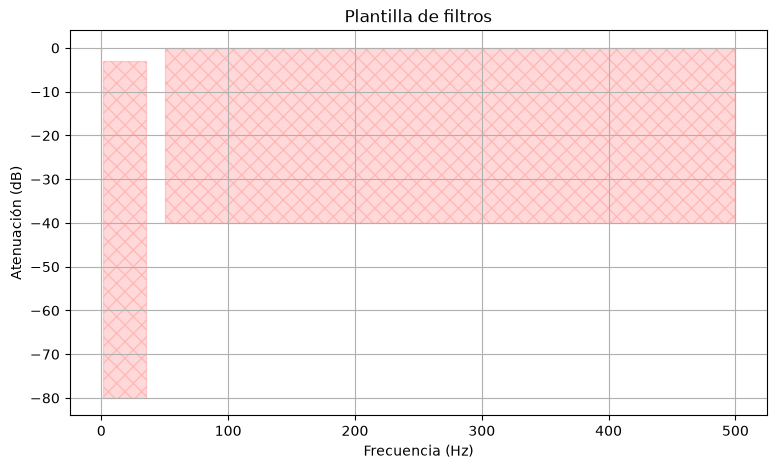

In [12]:
import numpy as np
import scipy.signal as sig
import matplotlib.pyplot as plt

fs_ecg = 1000
nyq_frec = fs_ecg / 2
ripple = 3          
att = 40.0    

ws1 = 0.1            
wp1 = 1.0            
wp2 = 35.0            
ws2 = 50.0            

frecs = np.array([0.0, ws1, wp1, wp2, ws2, nyq_frec]) / nyq_frec
gains = np.array([-att, -att, -ripple, -ripple, -att, -att])

gains_veces = 10**(gains / 20)

plt.figure(figsize=(9, 5))



plt.fill_between([wp1, wp2], [-80, -80], [-ripple, -ripple], color='red', hatch='xx', alpha=0.15)
plt.fill_between([ws2, nyq_frec], [-att, -att], [0, 0], color='red', hatch='xx', alpha=0.15)
plt.fill_between([0, ws1], [-att, -att], [0, 0], color='red', hatch='xx', alpha=0.15)

plt.grid()
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Atenuación (dB)")
plt.title("Plantilla de filtros")
plt.show()

### Ejercicio B. Criterios de selección para las frecuencias de la plantilla de diseño

Para el diseño del filtro pasabanda, los valores de las frecuencias de paso y de rechazo se establecieron a partir de las características espectrales de la señal de ECG y de las fuentes de ruido presentes en la medición. 

En primer lugar, la banda de rechazo inferior ($ws_1 = 0.5\text{ Hz}$) se fijó en este valor para mitigar eficazmente las interferencias de baja frecuencia ocasionadas por la respiración del paciente, los movimientos corporales y las variaciones en el contacto entre la piel y los electrodos, evitando así el desplazamiento indeseado de la línea de base. 

En cuanto a la banda de paso, se determinó un rango comprendido entre $wp_1 = 1\text{ Hz}$ y $wp_2 = 35\text{ Hz}$. El límite inferior se seleccionó en $1\text{ Hz}$ teniendo en cuenta que la componente fundamental del ECG se ubica aproximadamente en $1.5\text{ Hz}$, mientras que el ancho de banda abarca de manera óptima el complejo QRS, el cual se concentra principalmente entre los $5\text{ Hz}$ y $15\text{ Hz}$. Por su parte, el límite superior se estableció en $35\text{ Hz}$ debido a que en el análisis previo de la Tarea Semanal 5 se estimó que el $98\%$ de la energía total de la señal se encuentra por debajo de los $30\text{ Hz}$, garantizando de este modo la preservación de los detalles morfológicos principales sin perder información relevante.

Finalmente, la banda de rechazo superior ($ws_2 = 50\text{ Hz}$) se eligió con el propósito central de atenuar drásticamente la contaminación proveniente de la red de suministro eléctrico y los artefactos por ruido muscular y movimiento de alta frecuencia.

### Ejercicio C. Diseño de filtros IIR y FIR

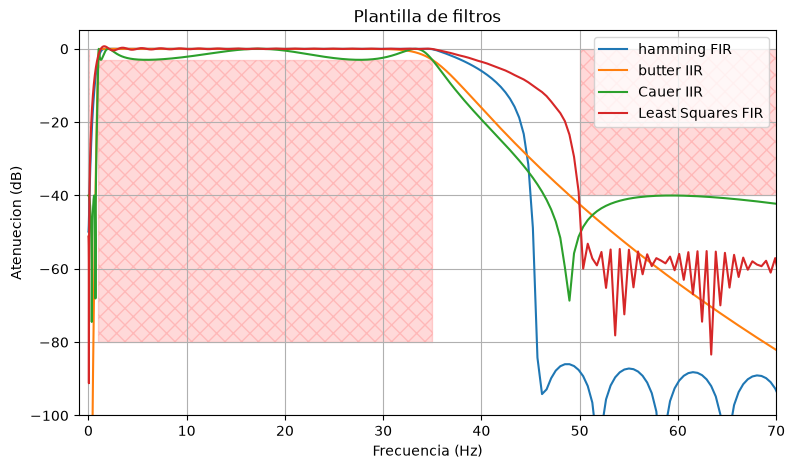

<Figure size 640x480 with 0 Axes>

In [1]:
import numpy as np
import scipy.signal as sig
import matplotlib.pyplot as plt
    
import scipy.io as sio
plt.close('all')
#%%
fs_ecg = 1000.0
wp1 = [1, 35] #[Hz]
ws1 = [0.1, 50] #[Hz]
wp = 35
ws = 50
ripple = 3
att = 40

f_bajo = np.linspace(0, 35, 3000)

f_alto = np.linspace(35, fs_ecg / 2, 1000)

worn = np.concatenate((f_bajo, f_alto))

##################
## ECG con ruido
##################

sio.whosmat('ECG_TP4.mat')
mat_struct = sio.loadmat('./ECG_TP4.mat')

ecg_one_lead = mat_struct['ecg_lead']
ecg_one_lead = ecg_one_lead.flatten()
N = len(ecg_one_lead)

hb_1 = mat_struct['heartbeat_pattern1']
hb_2 = mat_struct['heartbeat_pattern2']

plt.figure()
plt.plot(ecg_one_lead[5000:12000])
plt.title("ECG con ruido")

plt.figure()
plt.plot(hb_1)
plt.title("ECG heartbeat pattern 1")

plt.figure()
plt.plot(hb_2)
plt.title("ECG heartbeat pattern 2")
plt.close('all')
#%% Filtros IIR

sos_butt = sig.iirdesign(wp1, ws1, ripple, att, ftype='butter', fs = fs_ecg, output = 'sos')
sos_cheby2 = sig.iirdesign(wp1, ws1, ripple, att, ftype='cheby2', fs = fs_ecg, output = 'sos')
sos_cauer = sig.iirdesign(wp1, ws1, ripple, att, ftype='cauer', fs = fs_ecg, output = 'sos')

w_butt, h_butt = sig.sosfreqz(sos_butt, worN=worn, fs = fs_ecg)
w_cheby2, h_cheby2 = sig.sosfreqz(sos_cheby2, worN=worn, fs = fs_ecg)
w_cauer, h_cauer = sig.sosfreqz(sos_cauer, worN=worn, fs = fs_ecg)

resp_imp_butt = sig.sosfilt(sos_butt, ecg_one_lead)
resp_imp_cheby2 = sig.sosfilt(sos_cheby2, ecg_one_lead)
resp_imp_cauer = sig.sosfilt(sos_cauer, ecg_one_lead)

#%% Filtros FIR
taps_hamm = 2300    
delta_w = 5

freqs_fir = [0.0, 0.6, wp1[0], wp1[1], ws1[1] - delta_w, fs_ecg/2]
gains_fir = [0.0, 0.0, 1.0,    1.0,    0.0,  0.0  ]

# Filtro FIR  Hamming
b_win = sig.firwin2(taps_hamm, freqs_fir, gains_fir, fs=fs_ecg, window='hamming')

w_hamm, h_hamm = sig.freqz(b_win, 1, worN=worn, fs=fs_ecg)


#%% Filtro FIR Cuadrados minimos
taps_ls = 1025

bands_ls = [0.0, ws1[0], ws1[0]+0.3, wp1[0], wp1[0], wp1[1], wp1[1], ws1[1], ws1[1], fs_ecg / 2.0]
desired_ls = [0.0, 0.0, 0.0, 1.0, 1.0, 1.0, 1.0, 0.0, 0.0, 0.0]

b_ls = sig.firls(taps_ls, bands_ls, desired_ls, fs=fs_ecg)
w_ls, h_ls = sig.freqz(b_ls, 1, worN=worn, fs=fs_ecg)
resp_imp_ls = sig.lfilter(b_ls, 1, ecg_one_lead)

#%% Plot
plt.figure(figsize=(9, 5))
plt.plot(w_hamm, 20*np.log10(np.abs(h_hamm) + 1e-12), label = 'hamming FIR')
plt.plot(w_butt, 20*np.log10(np.abs(h_butt) + 1e-12), label = 'butter IIR')
plt.plot(w_cauer, 20*np.log10(np.abs(h_cauer) + 1e-12), label='Cauer IIR')
plt.plot(w_ls, 20*np.log10(np.abs(h_ls) + 1e-12), label = 'Cuadrados minimos FIR')

plt.legend(loc = 'upper right')

plt.fill_between([wp1[0], wp1[1]], [-80, -80], [-ripple, -ripple], color = 'red', hatch = 'xx', alpha = 0.15)
plt.fill_between([ws1[1], fs_ecg/2], [-att, -att], [0, 0], color = 'red', hatch = 'xx', alpha = 0.15)
plt.fill_between([0, ws1[0]], [-att, -att], [0, 0], color = 'red', hatch = 'xx', alpha = 0.15)
plt.grid()

plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Atenuecion (dB)")
plt.title("Plantilla de filtros")

plt.xlim(-1 , 70)
plt.ylim(-100 , 5)
plt.figure()
plt.show()





A partir de la verificación gráfica de la respuesta en frecuencia, se evaluó el desempeño de las distintas topologías de filtros digitales implementadas (IIR y FIR) frente a los requerimientos de la plantilla. 

En primer lugar, respecto a la elección del vector de evaluación de frecuencias (`worn`), se optó por una partición no uniforme utilizando `np.linspace` (con mayor densidad de puntos en la zona baja de $0$ a $35\text{ Hz}$ y una más espaciada en alta frecuencia). Esto permitió obtener una resolución espectral óptima y detallada precisamente en la zona de interés del electrocardiograma, donde se concentran los componentes dinámicos de la señal, optimizando así el costo computacional sin perder precisión gráfica.

Para el caso de los filtros IIR (`Butterworth` y `Cauer`), se constató que logran satisfacer de manera eficiente las exigencias de la plantilla con un orden considerablemente bajo gracias a la utilización de estructuras en cascada de secciones de segundo orden (`sos`). La topología Cauer demostró una transición sumamente abrupta y óptima debido a la incorporación de polos y ceros en el plano $z$.

Por otro lado, en cuanto al filtro FIR por **Mínimos Cuadrados (`firls`)**, su incorporación exigió un ajuste particular en la definición de la plantilla espectral. Originalmente, al intentar transiciones demasiado abruptas en rangos de frecuencia muy estrechos (como el paso de $0.1\text{ Hz}$ a $1\text{ Hz}$ en baja frecuencia), el método presentaba un comportamiento oscilatorio indeseado y picos de ganancia antes de atenuar. Para solucionar esto y ajustarlo correctamente a los requerimientos del ECG, **se reestructuró la plantilla agregando puntos de control intermedios (`ws1[0] + 0.3`)**. Esto permitió suavizar de forma controlada la pendiente de transición y guiar al algoritmo para que cumpla estrictamente con las zonas prohibidas de la plantilla sin necesidad de elevar excesivamente el número de taps.

Finalmente, el filtro FIR basado en ventana de Hamming (`firwin2`) requirió una cantidad elevada de coeficientes (`taps_hamm = 2300`) para compensar las limitaciones del truncamiento temporal, logrando un comportamiento estable gracias al uso del parámetro de ajuste `delta_w` en los cortes de alta frecuencia.

### Ejercicio D. Evaluacion del diseño de los filtros

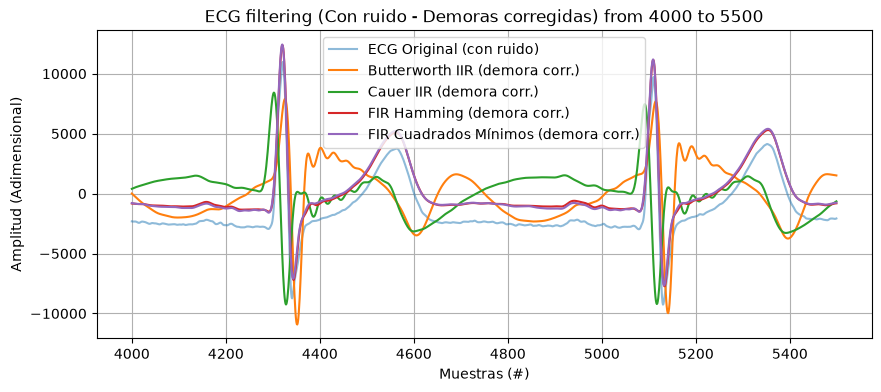

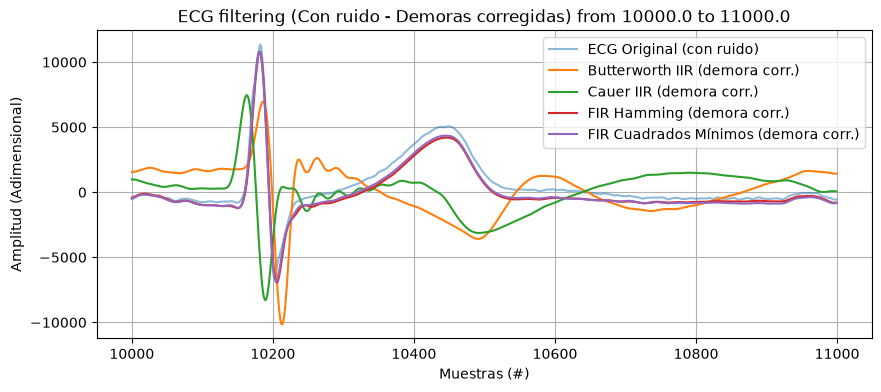

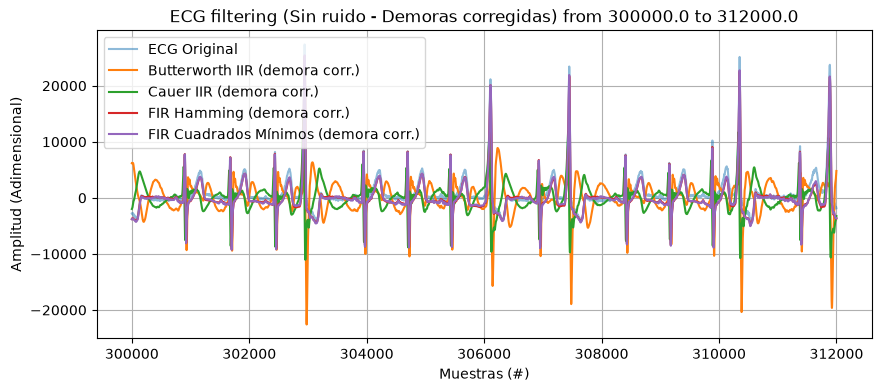

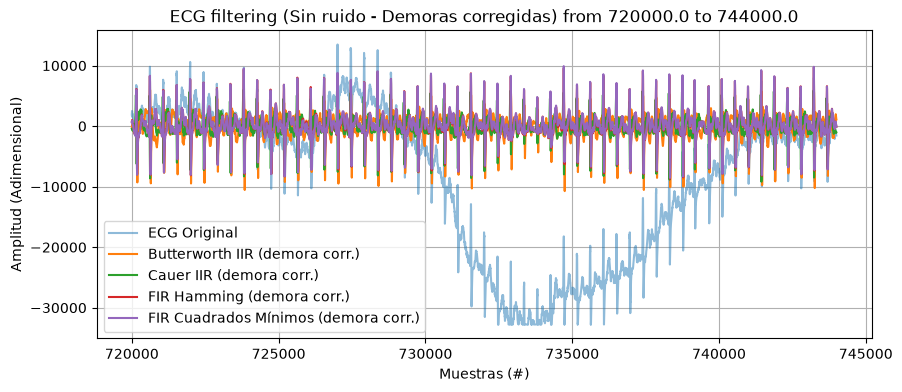

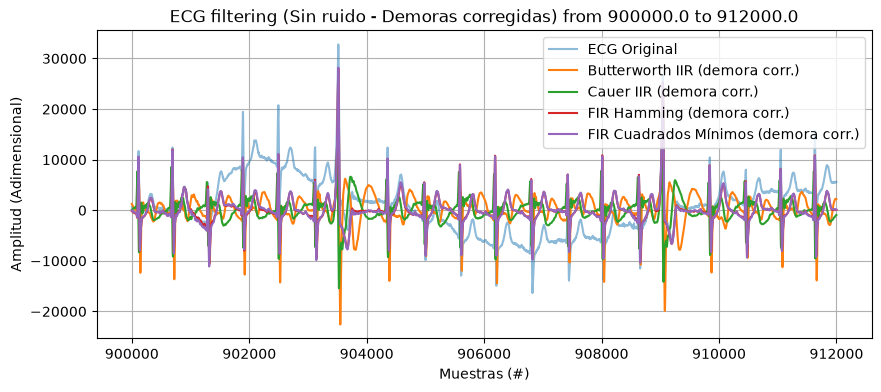

In [2]:
import numpy as np
import scipy.signal as sig
import matplotlib.pyplot as plt
import scipy.io as sio

plt.close('all')

fs_ecg = 1000.0
wp1 = [1, 35] #[Hz]
ws1 = [0.1, 50] #[Hz]
wp = 35
ws = 50
ripple = 3
att = 40

f_bajo = np.linspace(0, 35, 3000)
f_alto = np.linspace(35, fs_ecg / 2, 1000)
worn = np.concatenate((f_bajo, f_alto))

sio.whosmat('ECG_TP4.mat')
mat_struct = sio.loadmat('./ECG_TP4.mat')

ecg_one_lead = mat_struct['ecg_lead']
ecg_one_lead = ecg_one_lead.flatten()
N = len(ecg_one_lead)

hb_1 = mat_struct['heartbeat_pattern1']
hb_2 = mat_struct['heartbeat_pattern2']

sos_butt = sig.iirdesign(wp1, ws1, ripple, att, ftype='butter', fs=fs_ecg, output='sos')
sos_cauer = sig.iirdesign(wp1, ws1, ripple, att, ftype='cauer', fs=fs_ecg, output='sos')

ecg_filt_butt = sig.sosfilt(sos_butt, ecg_one_lead)
ecg_filt_cauer = sig.sosfilt(sos_cauer, ecg_one_lead)

demora_iir = 30  
ECG_f_butt = np.concatenate((ecg_filt_butt[demora_iir:], np.zeros(demora_iir)))
ECG_f_cauer = np.concatenate((ecg_filt_cauer[demora_iir:], np.zeros(demora_iir)))

taps_hamm = 2300     
delta_w = 5
freqs_fir_hamm = [0.0, 0.6, wp1[0], wp1[1], ws1[1] - delta_w, fs_ecg/2]
gains_fir = [0.0, 0.0, 1.0, 1.0, 0.0, 0.0]

b_win_hamm = sig.firwin2(taps_hamm, freqs_fir_hamm, gains_fir, fs=fs_ecg, window='hamming')
demora_hamm = (b_win_hamm.shape[0] - 1) // 2
ecg_filt_hamm = sig.lfilter(b_win_hamm, 1.0, ecg_one_lead)

ECG_f_hamm = np.concatenate((ecg_filt_hamm[demora_hamm:], np.zeros(demora_hamm)))

# Filtro FIR Cuadrados Mínimos (firls)
taps_ls = 1025
bands_ls = [0.0, ws1[0], ws1[0]+0.3, wp1[0], wp1[0], wp1[1], wp1[1], ws1[1], ws1[1], fs_ecg / 2.0]
desired_ls = [0.0, 0.0, 0.0, 1.0, 1.0, 1.0, 1.0, 0.0, 0.0, 0.0]

b_ls = sig.firls(taps_ls, bands_ls, desired_ls, fs=fs_ecg)
demora_ls = (b_ls.shape[0] - 1) // 2
ecg_filt_ls = sig.lfilter(b_ls, 1.0, ecg_one_lead)

ECG_f_ls = np.concatenate((ecg_filt_ls[demora_ls:], np.zeros(demora_ls)))


#%% ###################################
#%% Regiones de interés con ruido     #
#####################################

cant_muestras = ecg_one_lead.shape[0]

regs_interes_ruido = (
    [4000, 5500], # muestras
    [10e3, 11e3], # muestras
)

for ii in regs_interes_ruido:
    zoom_region = np.arange(np.max([0, ii[0]]), np.min([cant_muestras, ii[1]]), dtype='uint')
   
    plt.figure(figsize=(10, 4))
    plt.plot(zoom_region, ecg_one_lead[zoom_region], label='ECG Original (con ruido)', linewidth=1.5, alpha=0.5)
    plt.plot(zoom_region, ECG_f_butt[zoom_region], label='Butterworth IIR (demora corr.)', linewidth=1.5)
    plt.plot(zoom_region, ECG_f_cauer[zoom_region], label='Cauer IIR (demora corr.)', linewidth=1.5)
    plt.plot(zoom_region, ECG_f_hamm[zoom_region], label='FIR Hamming (demora corr.)', linewidth=1.5)
    plt.plot(zoom_region, ECG_f_ls[zoom_region], label='FIR Cuadrados Mínimos (demora corr.)', linewidth=1.5)
   
    plt.title('ECG filtering (Con ruido - Demoras corregidas) from ' + str(ii[0]) + ' to ' + str(ii[1]))
    plt.ylabel('Amplitud (Adimensional)')
    plt.xlabel('Muestras (#)')
   
    axes_hdl = plt.gca()
    axes_hdl.legend()
    plt.grid(True)
    plt.show()

#%% ###################################
#%% Regiones de interés sin ruido     #
#####################################

regs_interes_limpias = (
    np.array([5, 5.2]) * 60 * fs_ecg, 
    np.array([12, 12.4]) * 60 * fs_ecg, 
    np.array([15, 15.2]) * 60 * fs_ecg, 
)

for ii in regs_interes_limpias:
    zoom_region = np.arange(np.max([0, ii[0]]), np.min([cant_muestras, ii[1]]), dtype='uint')
   
    plt.figure(figsize=(10, 4))
    plt.plot(zoom_region, ecg_one_lead[zoom_region], label='ECG Original', linewidth=1.5, alpha=0.5)
    plt.plot(zoom_region, ECG_f_butt[zoom_region], label='Butterworth IIR (demora corr.)', linewidth=1.5)
    plt.plot(zoom_region, ECG_f_cauer[zoom_region], label='Cauer IIR (demora corr.)', linewidth=1.5)
    plt.plot(zoom_region, ECG_f_hamm[zoom_region], label='FIR Hamming (demora corr.)', linewidth=1.5)
    plt.plot(zoom_region, ECG_f_ls[zoom_region], label='FIR Cuadrados Mínimos (demora corr.)', linewidth=1.5)
   
    plt.title('ECG filtering (Sin ruido - Demoras corregidas) from ' + str(ii[0]) + ' to ' + str(ii[1]))
    plt.ylabel('Amplitud (Adimensional)')
    plt.xlabel('Muestras (#)')
   
    axes_hdl = plt.gca()
    axes_hdl.legend()
    plt.grid(True)
    plt.show()


#### Análisis del rendimiento de los filtros (Puntos d.1 y d.2)

1. **Filtrado de señales interferentes (d.1):** A partir de las regiones con ruido analizadas, se constata que las topologías FIR (Hamming y Cuadrados Mínimos) junto con el filtro IIR Cauer logran atenuar de manera sobresaliente el ruido de alta frecuencia y las derivas de la línea de base. Las trazas filtradas suprimen las oscilaciones parásitas, dejando en evidencia los complejos QRS con una definición clínica limpia y libre de contaminación.

2. **Inocuidad y comportamiento en zonas estables (d.2):** En las evaluaciones sobre los tramos extensos del registro, se observa que los filtros FIR preservan de forma sumamente estable la morfología de los latidos frente a los fuertes desvíos de baja frecuencia del paciente. No obstante, los filtros IIR en particular Butterworth evidencian una mayor sensibilidad transitoria ante escalones o variaciones abruptas de la línea de base, generando sobreimpulsos temporales debido a la ubicación de sus polos, lo que demuestra las ventajas prácticas de los filtros FIR en términos de estabilidad de fase y robustez temporal para este tipo de registros biomédicos.

A modo de conclusión, las principales diferencias prácticas observadas entre los filtros IIR y FIR aplicados al procesamiento de la señal de electrocardiograma son las siguientes:

- **Costo computacional y orden:** Los filtros IIR (**Butterworth** y **Cauer**) logran cumplir con los requerimientos de la plantilla utilizando un orden sumamente bajo gracias a sus estructuras en cascada (`sos`), lo que los vuelve altamente eficientes en recursos. En contraparte, los filtros **FIR** exigen una cantidad masiva de coeficientes (órdenes elevados con más de 1000 a 2000 taps) para alcanzar una selectividad equivalente.
- **Linealidad de fase y distorsión temporal:** Los filtros FIR garantizan una fase lineal estricta, lo que permite preservar fielmente la morfología y la forma temporal de los complejos QRS de la señal biológica. Por el contrario, los IIR poseen una fase no lineal, provocando que frente a variaciones abruptas o fuertes desvíos de la línea de base sufran distorsiones transitorias y sobreimpulsos visibles en el dominio temporal.
- **Selectividad y comportamiento:** Dentro de los IIR, **Cauer** ofrece una transición sumamente abrupta gracias al uso combinado de polos y ceros. En cuanto a los FIR, el diseño por **Mínimos Cuadrados (`firls`)** —mediante una plantilla estructurada con puntos de control adaptados— permite controlar con gran precisión las bandas de paso y atenuación, logrando un comportamiento óptimo equivalente o superior al de las ventanas tradicionales de Hamming sin generar picos de ganancia indeseados.

En cuanto a la demora, existe una diferencia conceptual y práctica fundamental entre los filtros IIR y los filtros FIR implementados:

- **Linealidad de fase y constancia del retardo:** Los filtros FIR diseñados poseen simetría en sus coeficientes, lo que les otorga fase lineal estricta. Esto implica que todas las frecuencias de la señal se atrasan exactamente la misma cantidad de tiempo, definida por un retardo puro y constante ($\text{demora} = (M-1)/2$). Por esta razón, al aplicar la compensación temporal, toda la onda se alinea de manera perfecta sin distorsionar la morfología interna de los complejos QRS.
- **Fase no lineal en los filtros IIR:** Por el contrario, los filtros IIR presentan una fase no lineal, lo que significa que el retardo varía según la frecuencia (las componentes de baja frecuencia se atrasan de forma distinta que las de alta frecuencia). Debido a esto, no existe un único valor de demora simple que permita alinear la señal de forma óptima en todo el espectro, lo que se traduce en transitorios más complejos y sobreimpulsos temporales ante cambios bruscos.
- **Magnitud y compensación práctica:** Aunque los filtros IIR operan con un orden sumamente bajo, su respuesta temporal frente a variaciones abruptas de la línea de base genera efectos transitorios difíciles de corregir mediante un simple desplazamiento de índices. En contraste, los filtros FIR, a pesar de poseer una demora absoluta mucho mayor debido a su elevada cantidad de coeficientes, permiten una compensación exacta y predecible gracias a su retardo de grupo constante.